In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import os
import glob
import numpy as np
import s3fs
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

# Xarray dark mode hack
from IPython.display import HTML, display

display(HTML("""
<style>
    .xr-wrap {
        --xr-background-color-row-odd: rgba(100, 100, 100, 0.10) !important;
        --xr-background-color-row-even: rgba(30, 30, 30, 0.10) !important;
    }
</style>
"""))

In [2]:
fs = s3fs.S3FileSystem(
    key=os.environ["AWS_ACCESS_KEY_ID"],
    secret=os.environ["AWS_SECRET_ACCESS_KEY"],
    client_kwargs={"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    config_kwargs={
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
                }
)

storage_options = {
    "client_kwargs": {"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    "config_kwargs": {
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
    },
}

In [28]:
runoff_zi = xr.open_dataset('s3://gaia/cjense/data/mar/basin_meltwater_regridded_daily_ZI_2000_2025.zarr', storage_options=storage_options, consolidated=False)

In [30]:
runoff_zi.SECTOR

<xarray.DataArray 'SECTOR' ()> Size: 4B
[1 values with dtype=float32]
Coordinates:
    SECTOR       float32 4B ...
    crs          int64 8B ...
    name         <U4 16B ...
    spatial_ref  int64 8B ...
    time1        datetime64[ns] 8B ...
    time         datetime64[ns] 8B ...
    time2        datetime64[ns] 8B ...
Attributes:
    units:          level
    long_name:      sector
    positive:       down
    point_spacing:  even
    axis:           Z
    standard_name:  depth

In [19]:
runoff_zi.RU[0].mean()

<xarray.DataArray 'RU' ()> Size: 4B
array(3.5138004e-07, dtype=float32)
Coordinates:
    SECTOR       float32 4B ...
    TIME         datetime64[ns] 8B 1999-12-30T12:00:00
    crs          int64 8B ...
    name         <U4 16B ...
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B ...
    time1        datetime64[ns] 8B ...
    time2        datetime64[ns] 8B ...
Attributes:
    long_name:  Run-off of meltwater and rain water
    units:      mmWE/day

In [34]:
ru_day

<xarray.DataArray 'RU' ()> Size: 4B
array(1.4322007e-06, dtype=float32)
Coordinates:
    TIME         datetime64[ns] 8B 2000-06-08T12:00:00
    SECTOR       float32 4B ...
    crs          int64 8B ...
    name         <U4 16B ...
    spatial_ref  int64 8B ...
    time1        datetime64[ns] 8B ...
    time         datetime64[ns] 8B ...
    time2        datetime64[ns] 8B ...
Attributes:
    long_name:  Run-off of meltwater and rain water
    units:      mmWE/day

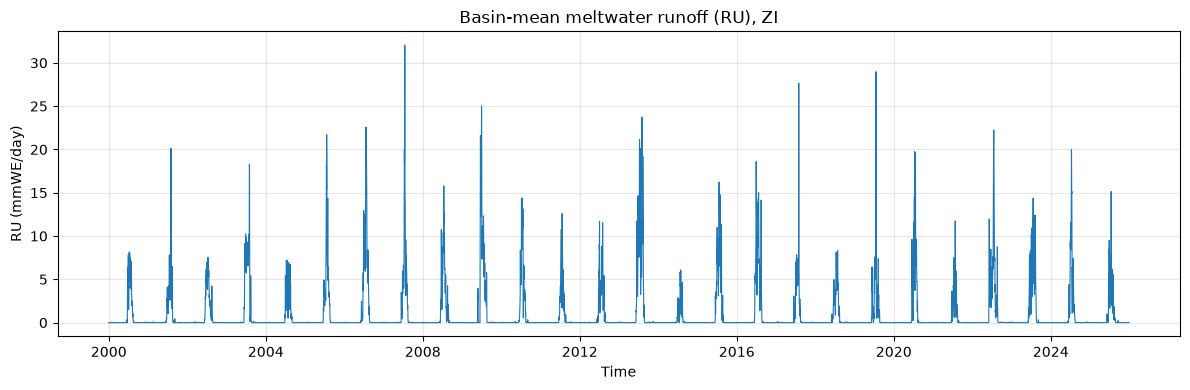

In [35]:
# Basin-mean runoff time series (NaNs outside the basin are skipped)
ru_mean = runoff_zi.RU.mean(dim=['x', 'y']).compute()

fig, ax = plt.subplots(figsize=(12, 4))
ru_mean.plot(ax=ax, x='TIME', color='tab:blue', linewidth=0.8)

ax.set_title("Basin-mean meltwater runoff (RU), ZI")
ax.set_xlabel("Time")
ax.set_ylabel(f"RU ({runoff_zi.RU.attrs.get('units', '')})")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# Daily climatology: mean runoff at each pixel for each day of year, across 2000–2025
ru_daily = runoff_zi.RU.groupby('TIME.dayofyear').mean(dim='TIME').compute()
ru_daily

: 

In [ ]:
# Plot the mean for a single day of year (e.g. 196 ≈ July 15)
doy = 196
ru_doy = ru_daily.sel(dayofyear=doy)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.pcolormesh(
    ru_doy.x,
    ru_doy.y,
    ru_doy,
    cmap="Blues",
    shading="auto",
)
fig.colorbar(im, ax=ax, label=f"RU ({runoff_zi.RU.attrs.get('units', '')})")

ax.set_title(f"Mean meltwater runoff (RU), day of year {doy}, 2000–2025")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")

plt.show()

NameError: name 'ru_daily' is not defined